# PhonePe Data Analysis Project

In this project, I am exploring PhonePe transaction data from 2018 to 2021. 

## 1. Import libraries

In [1]:
%pip install matplotlib
%pip install openpyxl


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt


## 2. Load the data
Using `phonepe_data.xlsx` file.
Making additional column for quarterly period

In [3]:
file = 'phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx'

state_txn = pd.read_excel(file, sheet_name='State_Txn and Users')
state_split = pd.read_excel(file, sheet_name='State_TxnSplit')
state_device = pd.read_excel(file, sheet_name='State_DeviceData')
district_txn = pd.read_excel(file, sheet_name='District_Txn and Users')
district_demo = pd.read_excel(file, sheet_name='District Demographics')
state_txn['Period'] = state_txn['Year'].astype(str) + ' Q' + state_txn['Quarter'].astype(str)


## 3. Look at the data

Checking rows first so I can understand what each table contains.

In [4]:
state_txn.head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens,Period
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0,2018 Q1
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0,2018 Q2
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0,2018 Q3
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0,2018 Q4
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0,2019 Q1


In [5]:
state_split.head()

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,1.213866e+07,6487.790112
2,Andaman & Nicobar Islands,2018,1,Merchant payments,298,4.525072e+05,1518.480432
3,Andaman & Nicobar Islands,2018,1,Financial Services,33,1.060142e+04,321.255149
4,Andaman & Nicobar Islands,2018,1,Others,256,1.846899e+05,721.444790


In [6]:
state_device.head()

,State,Year,Quarter,Brand,Registered Users,Percentage
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.247033
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.214392
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.145697
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.074332
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.049258


In [7]:
district_txn.head()

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0


In [8]:
district_demo.head()

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0,275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,5151549,10807.0,477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,4889230,11391.0,429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,2884524,15359.0,188,AP13,YSR


## 4. Check columns and data types

In [9]:
state_txn.info()

<class 'pandas.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             504 non-null    str    
 1   Year              504 non-null    int64  
 2   Quarter           504 non-null    int64  
 3   Transactions      504 non-null    int64  
 4   Amount (INR)      503 non-null    float64
 5   ATV (INR)         504 non-null    float64
 6   Registered Users  504 non-null    int64  
 7   App Opens         504 non-null    int64  
 8   Period            504 non-null    str    
dtypes: float64(2), int64(5), str(2)
memory usage: 35.6 KB


In [10]:
district_txn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10248 entries, 0 to 10247
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             10248 non-null  str    
 1   Year              10248 non-null  int64  
 2   Quarter           10248 non-null  int64  
 3   District          10248 non-null  str    
 4   Code              10220 non-null  str    
 5   Transactions      10248 non-null  int64  
 6   Amount (INR)      10248 non-null  float64
 7   ATV (INR)         10244 non-null  float64
 8   Registered Users  10248 non-null  int64  
 9   App Opens         10248 non-null  int64  
dtypes: float64(2), int64(5), str(3)
memory usage: 800.8 KB


## 5. Check missing values


In [11]:
state_txn.isnull().sum()

State               0
Year                0
Quarter             0
Transactions        0
Amount (INR)        1
ATV (INR)           0
Registered Users    0
App Opens           0
Period              0
dtype: int64

In [12]:
district_txn.isnull().sum()

State                0
Year                 0
Quarter              0
District             0
Code                28
Transactions         0
Amount (INR)         0
ATV (INR)            4
Registered Users     0
App Opens            0
dtype: int64

## 6. Basic summary

In [13]:
state_txn.describe()

,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,504.000000,504.000000,5.040000e+02,5.030000e+02,504.000000,5.040000e+02,5.040000e+02
mean,2019.285714,2.357143,4.074000e+07,7.083332e+10,1993.471543,4.777501e+06,9.774471e+07
std,1.031181,1.109971,8.228714e+07,1.440902e+11,607.464894,6.644496e+06,2.042376e+08
min,2018.000000,1.000000,7.780000e+02,1.928611e+06,0.000000,5.010000e+02,0.000000e+00
25%,2018.000000,1.000000,5.925578e+05,1.167157e+09,1598.910667,1.574202e+05,0.000000e+00
50%,2019.000000,2.000000,6.217487e+06,1.051605e+10,1861.380589,1.747914e+06,2.930574e+06
75%,2020.000000,3.000000,4.363675e+07,6.947045e+10,2259.087924,7.320945e+06,8.615022e+07
max,2021.000000,4.000000,5.736165e+08,1.027958e+12,3938.733850,3.966470e+07,1.208084e+09


## 7. How many states and districts are in the data?

In [14]:
print('Number of states:', district_txn['State'].nunique())
print('Number of districts:', district_txn['District'].nunique())

Number of states: 36
Number of districts: 723


## 8. Total transactions by state

In [15]:
state_sales = state_txn.groupby('State')['Transactions'].sum()
state_sales = state_sales.sort_values(ascending=False)
state_sales.head(10)

State
Karnataka         2981044533
Maharashtra       2833670154
Telangana         2347430243
Andhra Pradesh    1781091169
Rajasthan         1382918930
Uttar Pradesh     1314714390
Madhya Pradesh    1100253728
Delhi             1011031124
West Bengal        942286041
Tamil Nadu         800399873
Name: Transactions, dtype: int64

The table above shows the 10 states with the highest total number of transactions in the available period.

## 9. States with the lowest transactions

In [16]:
state_sales.tail(10)

State
Manipur                      12318043
Tripura                      12018152
Arunachal Pradesh             8043799
Sikkim                        6483948
Nagaland                      5864977
Meghalaya                     5648913
Mizoram                       2162776
Ladakh                        1880109
Andaman & Nicobar Islands     1223565
Lakshadweep                     71610
Name: Transactions, dtype: int64

## 10. Chart: top 10 states by transactions

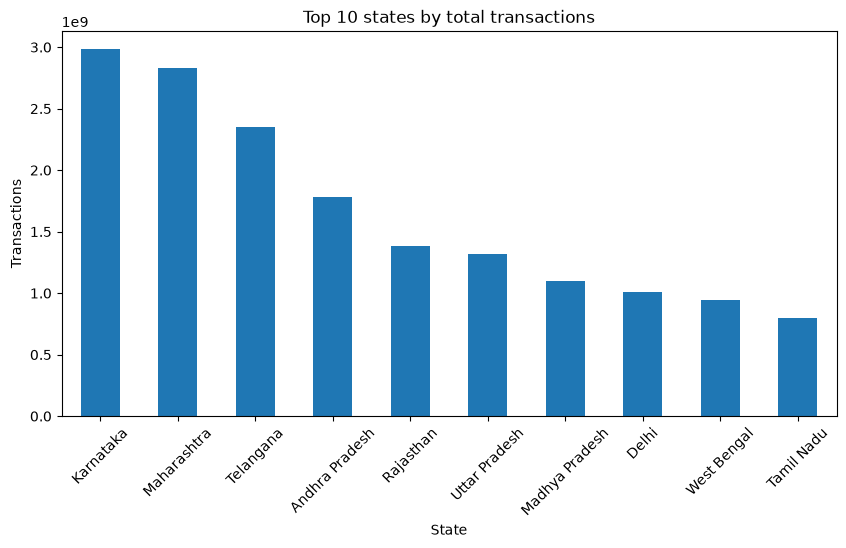

In [17]:
top_states = state_sales.head(10)

top_states.plot(kind='bar', figsize=(10, 5))
plt.title('Top 10 states by total transactions')
plt.xlabel('State')
plt.ylabel('Transactions')
plt.xticks(rotation=45)
plt.show()

## 11. Total transaction amount by state

In [18]:
state_amount = state_txn.groupby('State')['Amount (INR)'].sum()
state_amount.sort_values(ascending=False).head(10)

State
Telangana         4.574246e+12
Karnataka         4.361396e+12
Maharashtra       4.290995e+12
Andhra Pradesh    3.187847e+12
Rajasthan         2.625584e+12
Uttar Pradesh     2.399757e+12
Madhya Pradesh    1.915101e+12
Delhi             1.649942e+12
Bihar             1.639579e+12
Tamil Nadu        1.481448e+12
Name: Amount (INR), dtype: float64

## 12. Transaction types

Calculating most used transaction types.

In [19]:
transaction_types = state_split.groupby('Transaction Type')['Transactions'].sum()
transaction_types = transaction_types.sort_values(ascending=False)
transaction_types

Transaction Type
Peer-to-peer payments       9161937793
Merchant payments           6959228853
Recharge & bill payments    4245833207
Others                       117964108
Financial Services            47996333
Name: Transactions, dtype: int64

## 13. Chart: transaction types

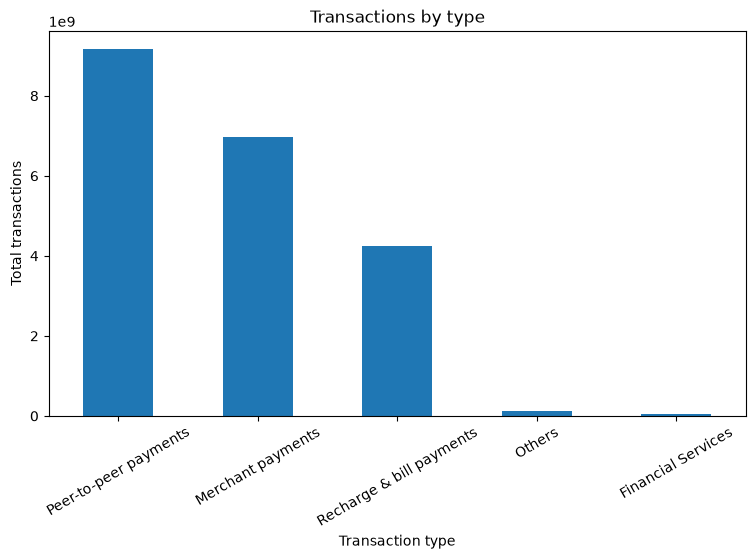

In [31]:
transaction_types.plot(kind='bar', figsize=(9, 5))
plt.title('Transactions by type')
plt.xlabel('Transaction type')
plt.ylabel('Total transactions')
plt.xticks(rotation=30)
plt.show()

## 14. Most used device brands in the latest quarter

Registered users are running totals, so I am looking at the latest quarter instead of adding users from every quarter.

In [21]:
latest_year = state_device['Year'].max()
latest_quarter = state_device[state_device['Year'] == latest_year]['Quarter'].max()

latest_devices = state_device[(state_device['Year'] == latest_year) & (state_device['Quarter'] == latest_quarter)]

brand_users = latest_devices.groupby('Brand')['Registered Users'].sum()
brand_users.sort_values(ascending=False).head(10)

Brand
Xiaomi      75948216
Samsung     59144529
Vivo        58646328
Oppo        38402666
Others      23207147
Realme      20619357
Apple        7936817
Motorola     5741618
Huawei       5067245
OnePlus      4711860
Name: Registered Users, dtype: int64

## 15. Chart: device brands

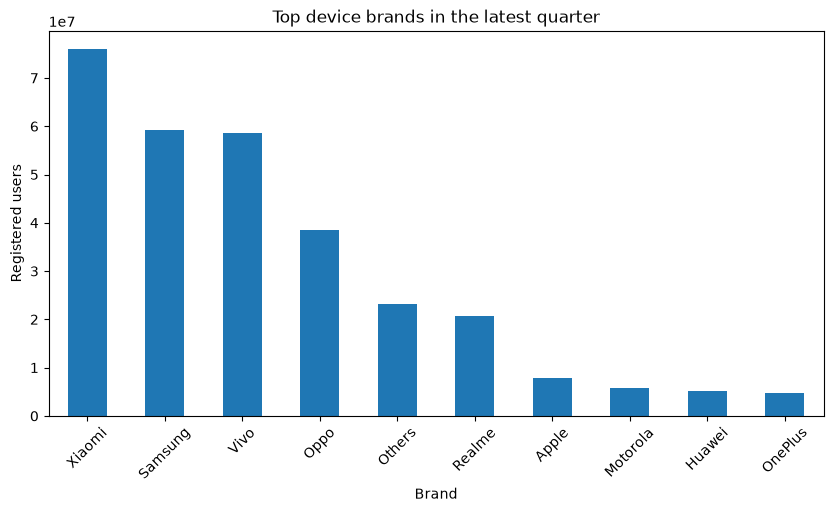

In [22]:
brand_users.sort_values(ascending=False).head(10).plot(kind='bar', figsize=(10, 5))
plt.title('Top device brands in the latest quarter')
plt.xlabel('Brand')
plt.ylabel('Registered users')
plt.xticks(rotation=45)
plt.show()

## 16. Most populated districts

In [23]:
district_demo[['State', 'District', 'Population']].sort_values('Population', ascending=False).head(10)

,State,District,Population
691,West Bengal,North 24 Parganas,10082852
235,Karnataka,Bangalore Urban,9588910
356,Maharashtra,Pune,9426959
348,Maharashtra,Mumbai suburban,9332481
695,West Bengal,South 24 Parganas,8161961
363,Maharashtra,Thane,8070032
140,Gujarat,Ahmedabad,7208200
509,Tamil Nadu,Chennai,7139882
689,West Bengal,Murshidabad,7102430
489,Rajasthan,Jaipur,6663971


## 17. Average transaction value by state

In [24]:
state_atv = state_txn.groupby('State')[['Amount (INR)', 'Transactions']].sum()
state_atv['Average Transaction Value'] = state_atv['Amount (INR)'] / state_atv['Transactions']
state_atv.sort_values('Average Transaction Value', ascending=False).head(10)

,Amount (INR),Transactions,Average Transaction Value
State,,,
Ladakh,6.606978e+09,1880109,3514.146494
Andaman & Nicobar Islands,3.641818e+09,1223565,2976.399178
Mizoram,6.317141e+09,2162776,2920.848685
Manipur,3.579325e+10,12318043,2905.757931
Nagaland,1.638757e+10,5864977,2794.140997
Arunachal Pradesh,2.225183e+10,8043799,2766.333539
Lakshadweep,1.921587e+08,71610,2683.405735
Jammu & Kashmir,1.094954e+11,45053328,2430.351780
Bihar,1.639579e+12,713643889,2297.474906


## 18. Quarterly transaction trend

This table shows how transactions changed over time across all states.

In [25]:
quarterly_txn = state_txn.groupby(['Year', 'Quarter'])['Transactions'].sum().reset_index()
quarterly_txn.head()

,Year,Quarter,Transactions
0,2018,1,134425599
1,2018,2,187365440
2,2018,3,341299764
3,2018,4,417111607
4,2019,1,708992981


In [26]:
quarterly_txn['Period'] = quarterly_txn['Year'].astype(str) + ' Q' + quarterly_txn['Quarter'].astype(str)
quarterly_txn

,Year,Quarter,Transactions,Period
0,2018,1,134425599,2018 Q1
1,2018,2,187365440,2018 Q2
2,2018,3,341299764,2018 Q3
3,2018,4,417111607,2018 Q4
4,2019,1,708992981,2019 Q1
5,2019,2,815380896,2019 Q2
6,2019,3,1095009675,2019 Q3
7,2019,4,1460443663,2019 Q4
8,2020,1,1623038046,2020 Q1
9,2020,2,1448608890,2020 Q2


## 19. Chart: transactions by quarter

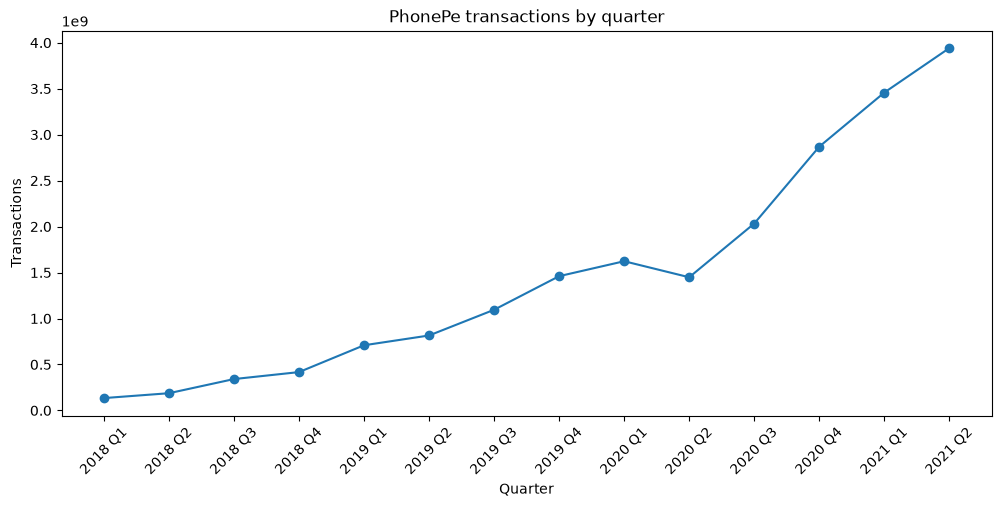

In [27]:
plt.figure(figsize=(12, 5))
plt.plot(quarterly_txn['Period'], quarterly_txn['Transactions'], marker='o')
plt.title('PhonePe transactions by quarter')
plt.xlabel('Quarter')
plt.ylabel('Transactions')
plt.xticks(rotation=45)
plt.show()

## 20. App opens for one state, taking Karnataka as example.

In [28]:
selected_state = 'Karnataka'
karnataka_data = state_txn[state_txn['State'] == selected_state]
karnataka_data[['Year', 'Quarter', 'App Opens']].head()

,Year,Quarter,App Opens
210,2018,1,0
211,2018,2,0
212,2018,3,0
213,2018,4,0
214,2019,1,0


## 21. Chart: app opens

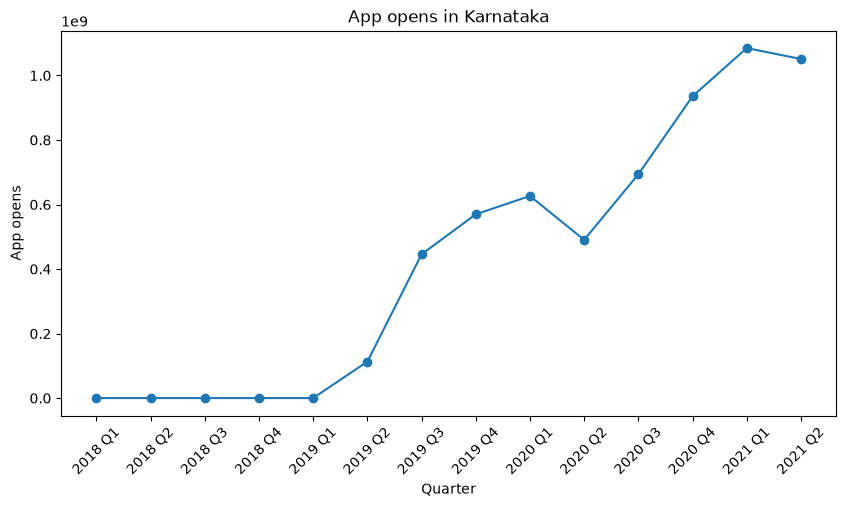

In [29]:
plt.figure(figsize=(10, 5))
plt.plot(karnataka_data['Period'], karnataka_data['App Opens'], marker='o')
plt.title('App opens in Karnataka')
plt.xlabel('Quarter')
plt.ylabel('App opens')
plt.xticks(rotation=45)
plt.show()

## 23. Conclusion

This project helped me practise loading Excel sheets, checking data, handling missing values, grouping and sorting data, and creating charts with Pandas and Matplotlib. The data in this project goes up to Q2 2021, so it does not represent current PhonePe usage.